# Assignment 3

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import cv2
from PIL import Image

In [2]:
def freq_to_spatial(img):
    return np.fft.ifft2(np.fft.ifftshift(img)).real

def butterworth_mask(shape, cutoff_freq, order):
    mask = np.zeros(shape, np.float32)
    x, y = shape
    for i in range(x):
        for j in range(y):
            mask[i,j]= (1 / (1 + (np.linalg.norm([i - (x // 2), j - (y // 2)], ord=2)/cutoff_freq)**(2 * order)))
    return mask

## Question 1

For the image toys.gif

**A)** Read and display the image.  
**B)** Compute the 2-D FFT of the image and display one full-scaled copy of the magnitude spectrum.  
**C)** Compute and display properly the inverse 2-D FFT of the phase component of the spectrum only.

<img src="./imgs/toys.gif" width="200" height="200"/>

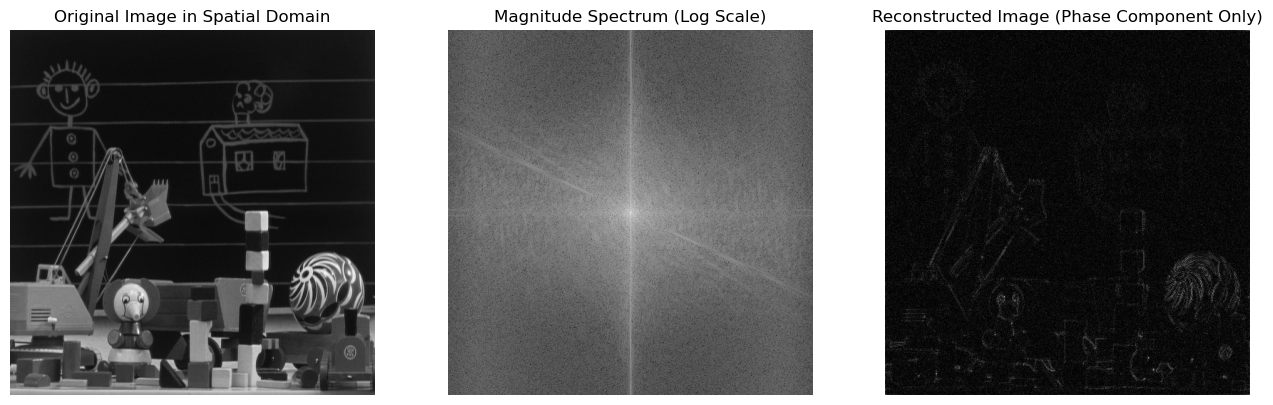

In [3]:
# Answer for A, B & C : Reading the image, computing the 2-D FFT, and displaying the magnitude spectrum and phase-only reconstruction.
ex1_image = Image.open('./imgs/toys.gif')
ex1_image = np.array(ex1_image)
ex1_fft = np.fft.fft2(ex1_image)
ex1_shift = np.fft.fftshift(ex1_fft)
ex1_magnitude = np.abs(ex1_shift)
ex1_magnitude_display = cv2.normalize(np.log1p(ex1_magnitude), None, 0, 255, cv2.NORM_MINMAX)
ex1_phase = np.angle(ex1_fft)

#e^jx = cos(x) + j sin(x)
inverse_phase = np.fft.ifft2(np.exp(1j * ex1_phase))
inverse_phase = np.abs(inverse_phase)

plt.figure(figsize=(16, 8))

plt.subplot(1,3,1)
plt.title('Original Image in Spatial Domain')
plt.axis('off')
plt.imshow(ex1_image, cmap='gray')

plt.subplot(1,3,2)
plt.title('Magnitude Spectrum (Log Scale)')
plt.axis('off')
plt.imshow(ex1_magnitude_display, cmap='gray')


plt.subplot(1,3,3)
plt.title('Reconstructed Image (Phase Component Only)')
plt.axis('off')
plt.imshow(inverse_phase, cmap='gray');
#plt.savefig('./results/q1.jpg', format='jpg', bbox_inches="tight", pad_inches=0)

## Question 2

For the image pepper.jpg, it is required to study the ringing effect of the Butterworth lowpass filter. Design the following filters and investigate the effect of changing the filter order and cutoff frequency on ringing. You need to display the filtered images and the shape of the filters in the spatial domain. A cross-sectional view of the filters in the spatial domain is required. Make sure to display the figures in a neat and organized way.

| Filter Number | Order | Cutoff Frequency |
|----------|----------|----------|
| 1 | 1 | 50 |
| 2 | 1 | 150 |
| 3 | 5 | 50 |
| 4 | 5 | 150 |

<img src="./imgs/pepper.jpg" width="200" height="200"/>

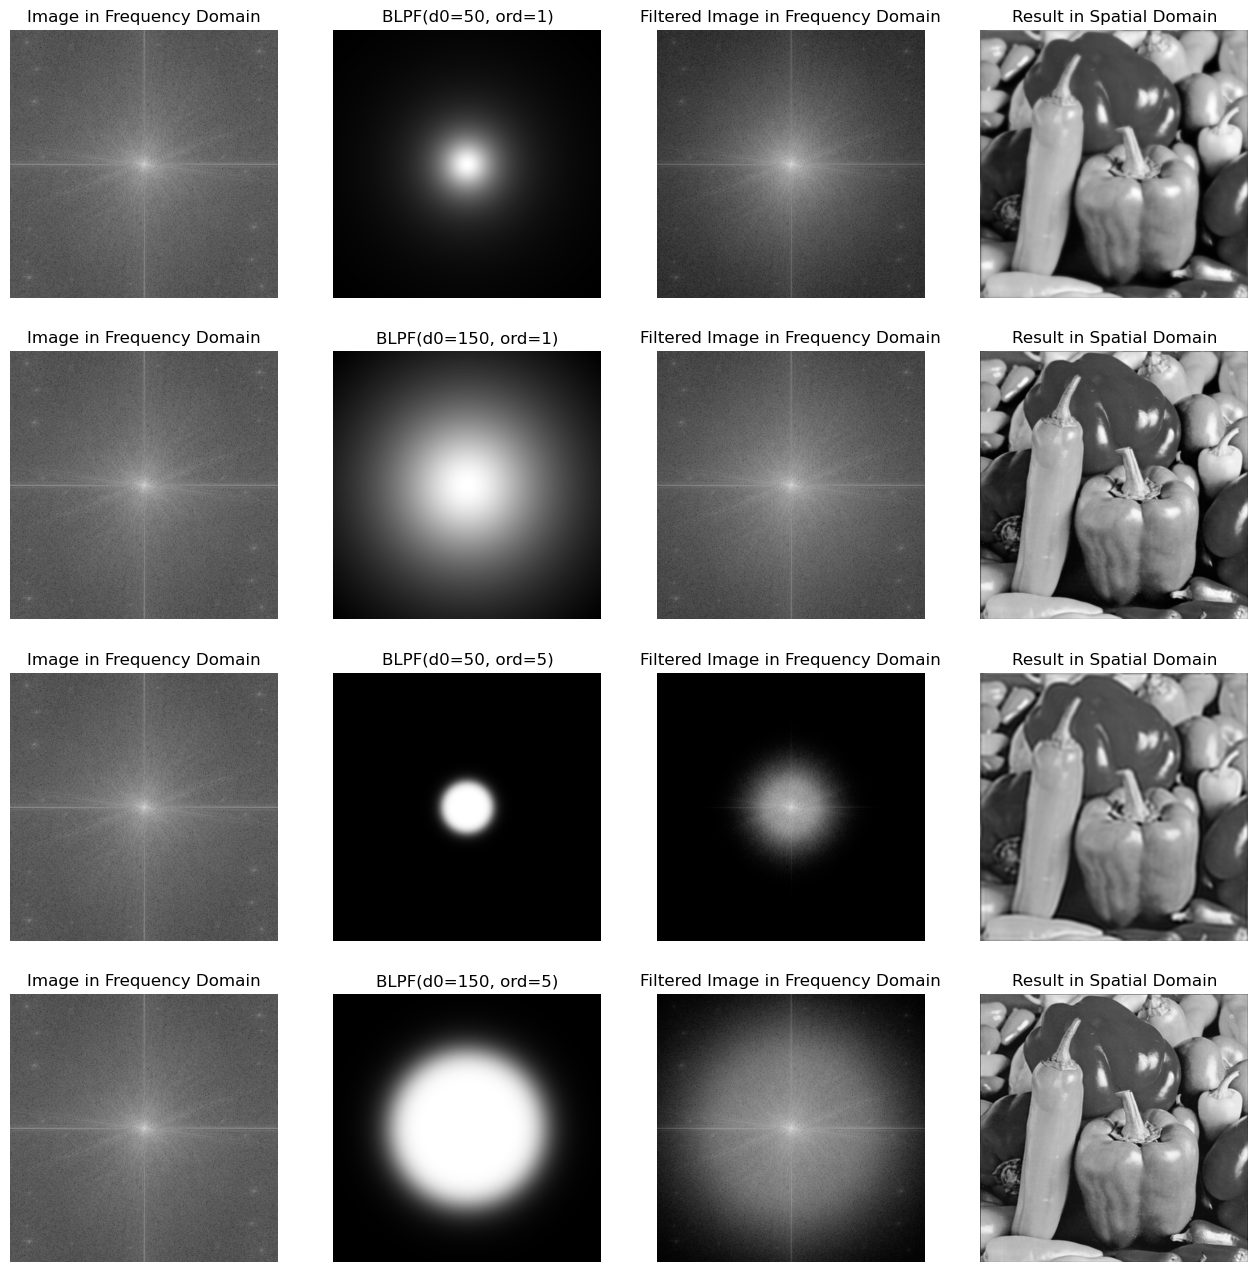

In [4]:
# Answer for A & B : Applying Butterworth low-pass filters with different cutoff frequencies and orders, and displaying the filtered images.

ex2_image = cv2.imread('./imgs/pepper.jpg', cv2.IMREAD_GRAYSCALE)
ex2_fft = np.fft.fft2(ex2_image)
ex2_shift = np.fft.fftshift(ex2_fft)
ex2_magnitude = np.abs(ex2_shift)

mask1 = butterworth_mask(ex2_image.shape, 50, 1)
mask2 = butterworth_mask(ex2_image.shape, 150, 1)
mask3 = butterworth_mask(ex2_image.shape, 50, 5)
mask4 = butterworth_mask(ex2_image.shape, 150, 5)

img1 = np.multiply(mask1, ex2_shift)
img2 = np.multiply(mask2, ex2_shift)
img3 = np.multiply(mask3, ex2_shift)
img4 = np.multiply(mask4, ex2_shift)

plt.figure(figsize=(16, 16))

plt.subplot(4, 4, 1)
plt.title('Image in Frequency Domain')
plt.axis('off')
plt.imshow(np.log1p(ex2_magnitude), cmap='gray')

plt.subplot(4, 4, 2)
plt.title('BLPF(d0=50, ord=1)')
plt.axis('off')
plt.imshow(mask1, cmap='gray')

plt.subplot(4, 4, 3)
plt.title('Filtered Image in Frequency Domain')
plt.axis('off')
plt.imshow(np.log1p(np.abs(img1)), cmap='gray')

plt.subplot(4, 4, 4)
plt.title('Result in Spatial Domain')
plt.axis('off')
plt.imshow(freq_to_spatial(img1), cmap='gray')

plt.subplot(4, 4, 5)
plt.title('Image in Frequency Domain')
plt.axis('off')
plt.imshow(np.log1p(ex2_magnitude), cmap='gray')

plt.subplot(4, 4, 6)
plt.title('BLPF(d0=150, ord=1)')
plt.axis('off')
plt.imshow(mask2, cmap='gray')

plt.subplot(4, 4, 7)
plt.title('Filtered Image in Frequency Domain')
plt.axis('off')
plt.imshow(np.log1p(np.abs(img2)), cmap='gray')

plt.subplot(4, 4, 8)
plt.title('Result in Spatial Domain')
plt.axis('off')
plt.imshow(freq_to_spatial(img2), cmap='gray')

plt.subplot(4, 4, 9)
plt.title('Image in Frequency Domain')
plt.axis('off')
plt.imshow(np.log1p(ex2_magnitude), cmap='gray')

plt.subplot(4, 4, 10)
plt.title('BLPF(d0=50, ord=5)')
plt.axis('off')
plt.imshow(mask3, cmap='gray')

plt.subplot(4, 4, 11)
plt.title('Filtered Image in Frequency Domain')
plt.axis('off')
plt.imshow(np.log1p(np.abs(img3)), cmap='gray')

plt.subplot(4, 4, 12)
plt.title('Result in Spatial Domain')
plt.axis('off')
plt.imshow(freq_to_spatial(img3), cmap='gray')

plt.subplot(4, 4, 13)
plt.title('Image in Frequency Domain')
plt.axis('off')
plt.imshow(np.log1p(ex2_magnitude), cmap='gray')

plt.subplot(4, 4, 14)
plt.title('BLPF(d0=150, ord=5)')
plt.axis('off')
plt.imshow(mask4, cmap='gray')

plt.subplot(4, 4, 15)
plt.title('Filtered Image in Frequency Domain')
plt.axis('off')
plt.imshow(np.log1p(np.abs(img4)), cmap='gray')

plt.subplot(4, 4, 16)
plt.title('Result in Spatial Domain')
plt.axis('off')
plt.imshow(freq_to_spatial(img4), cmap='gray');

#plt.savefig('./results/q2.jpg', format='jpg', bbox_inches="tight", pad_inches=0)

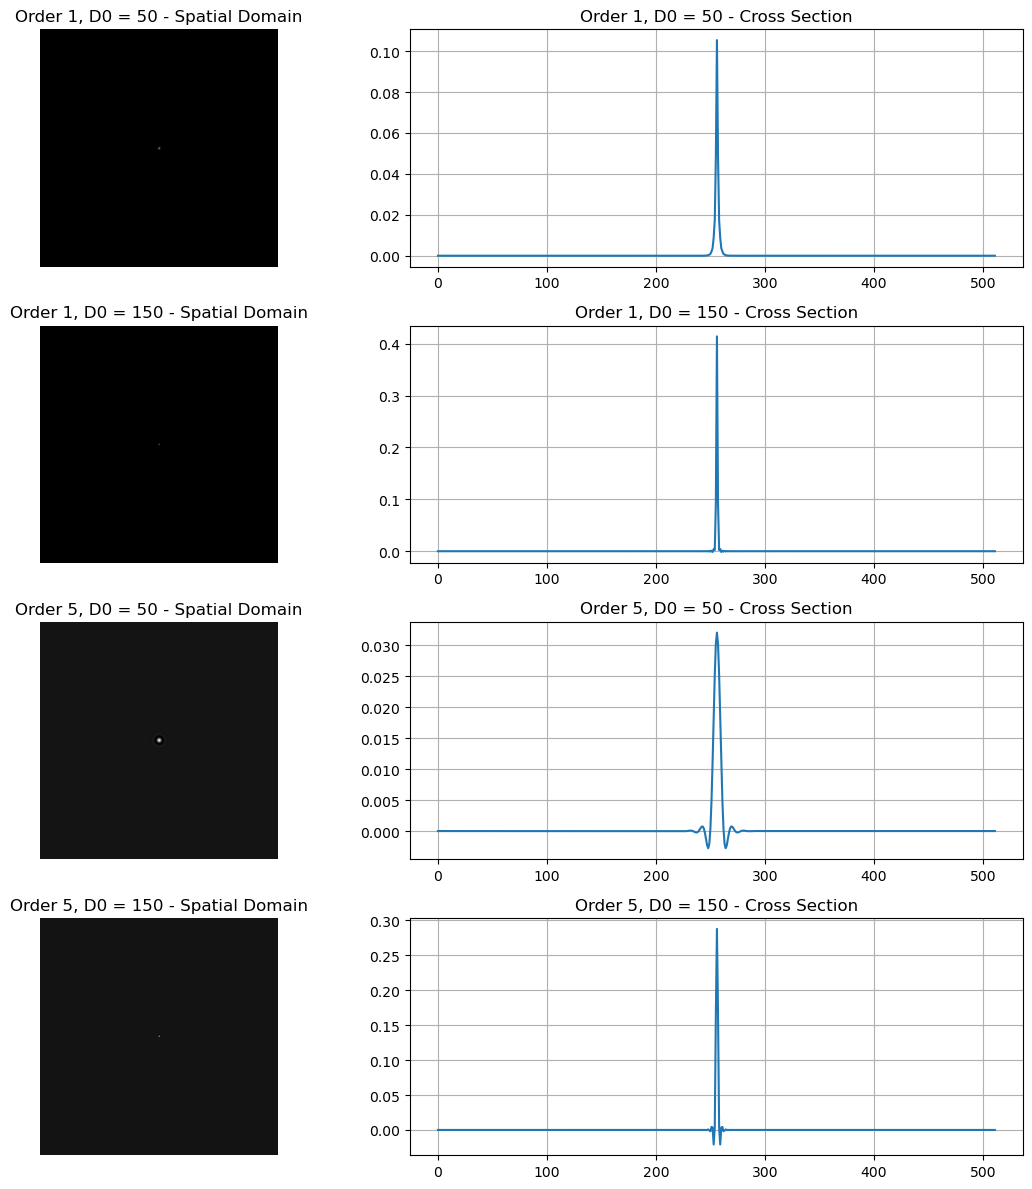

In [5]:
# Additional visualization : Displaying the spatial-domain filters and their cross-sectional views.

mask1_spatial = np.fft.fftshift(np.fft.ifft2(np.fft.ifftshift(mask1))).real
mask2_spatial = np.fft.fftshift(np.fft.ifft2(np.fft.ifftshift(mask2))).real
mask3_spatial = np.fft.fftshift(np.fft.ifft2(np.fft.ifftshift(mask3))).real
mask4_spatial = np.fft.fftshift(np.fft.ifft2(np.fft.ifftshift(mask4))).real

spatial_masks = [mask1_spatial, mask2_spatial, mask3_spatial, mask4_spatial]
filter_titles = ['Order 1, D0 = 50', 'Order 1, D0 = 150', 'Order 5, D0 = 50', 'Order 5, D0 = 150']

plt.figure(figsize=(12, 12))

for i in range(4):
    plt.subplot(4, 2, 2*i + 1)
    plt.title(filter_titles[i] + ' - Spatial Domain')
    plt.axis('off')
    plt.imshow(spatial_masks[i], cmap='gray')

    plt.subplot(4, 2, 2*i + 2)
    plt.title(filter_titles[i] + ' - Cross Section')
    plt.plot(spatial_masks[i][ex2_image.shape[0] // 2, :])
    plt.grid()

plt.tight_layout()
#plt.savefig('./results/q2-1.jpg', format='jpg', bbox_inches="tight", pad_inches=0)

## Question 3

For the image prob2_s2012.gif

**A)** Compute and display the magnitude spectrum of the image.     
**B)** Investigate the image in the spatial and frequency domains and determine the type of noise that is corrupting the image.     
**C)** Design the proper filter and use it to restore the original image.       
**D)** Based on the filter in part C, can you display the noise component in the spatial domain? If so, show the image that represents the noise.


<img src="./imgs/prob2_s2012.gif" width="200" height="200"/>

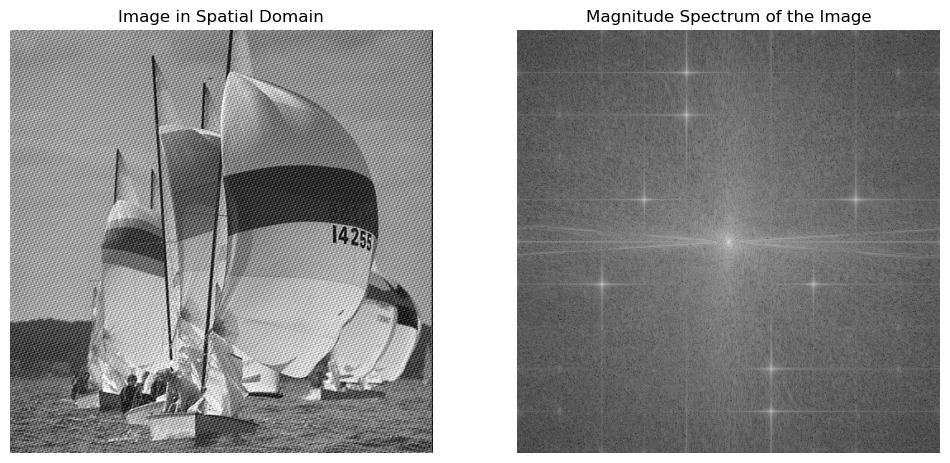

In [6]:
# Answer for A & B : Computing the magnitude spectrum and identifying the periodic noise.
ex3_image = Image.open('./imgs/prob2_s2012.gif')
ex3_image = np.array(ex3_image)
ex3_fft = np.fft.fft2(ex3_image)
ex3_shift = np.fft.fftshift(ex3_fft)
ex3_magnitude = np.abs(ex3_shift)

plt.figure(figsize=(12,8))

plt.subplot(1,2,1)
plt.title('Image in Spatial Domain')
plt.axis('off')
plt.imshow(ex3_image, cmap='gray')

plt.subplot(1,2,2)
plt.title('Magnitude Spectrum of the Image')
plt.axis('off')
plt.imshow(np.log1p(ex3_magnitude), cmap='gray');
#plt.savefig('./results/q3.jpg', format='jpg', bbox_inches="tight", pad_inches=0)

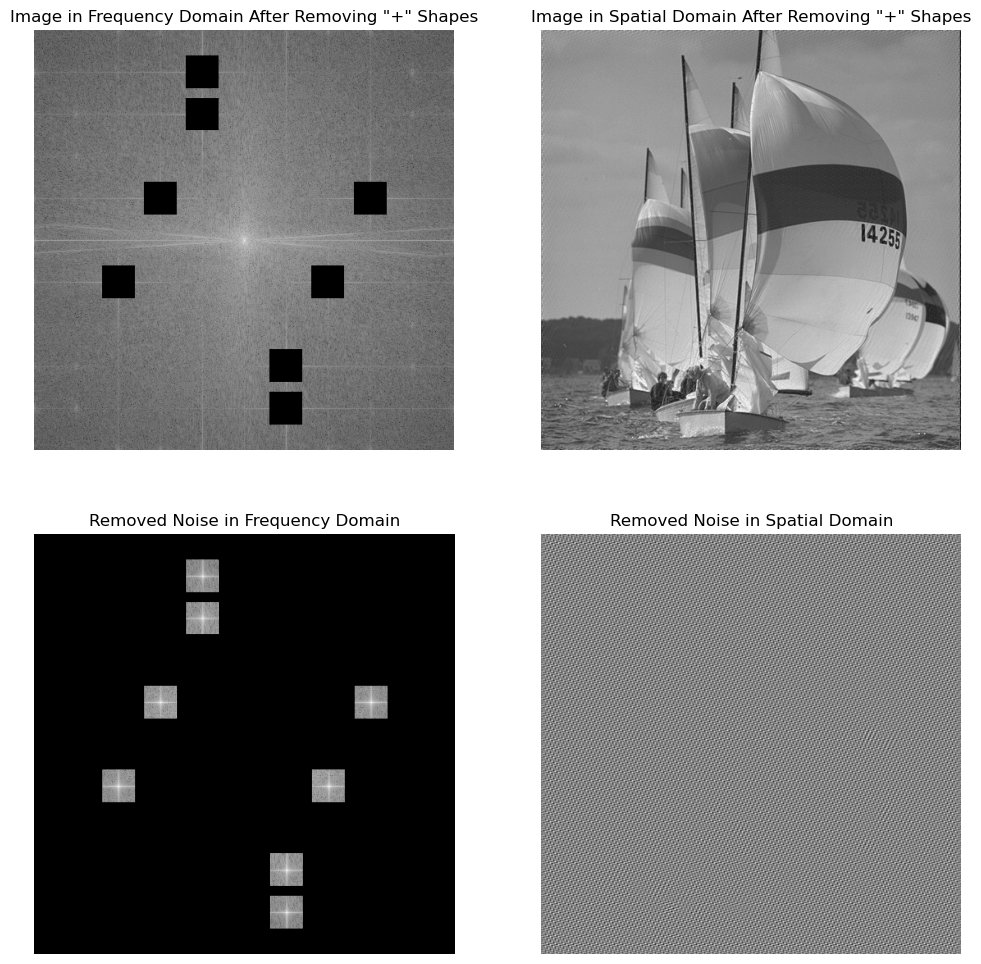

In [7]:
# Answer for C & D : Removing periodic noise using frequency-domain filtering and displaying the restored image and removed noise.
ex3_shift_org = ex3_shift.copy()
ex3_shift[31:71, 185:225] = 0
ex3_shift[83:122, 185:225] = 0
ex3_shift[185:225, 134:174] = 0
ex3_shift[389:429, 287:327] = 0
ex3_shift[441:481, 287:327] = 0
ex3_shift[287:327, 338:378] = 0
ex3_shift[287:327, 83:123] = 0
ex3_shift[185:225, 390:430] = 0

ex3_final = freq_to_spatial(ex3_shift)
ex3_removed_spatial_final = freq_to_spatial(ex3_shift_org - ex3_shift)

plt.figure(figsize=(12,12))

plt.subplot(2,2,1)
plt.title('Image in Frequency Domain After Removing "+" Shapes')
plt.axis('off')
plt.imshow(np.log1p(np.abs(ex3_shift)), cmap='gray')

plt.subplot(2,2,2)
plt.title('Image in Spatial Domain After Removing "+" Shapes')
plt.axis('off')
plt.imshow(ex3_final, cmap='gray')

plt.subplot(2,2,3)
plt.title('Removed Noise in Frequency Domain')
plt.axis('off')
plt.imshow(np.log1p(np.abs(ex3_shift_org - ex3_shift)), cmap='gray')

plt.subplot(2,2,4)
plt.title('Removed Noise in Spatial Domain')
plt.axis('off')
plt.imshow(ex3_removed_spatial_final, cmap='gray');
#plt.savefig('./results/q3-1.jpg', format='jpg', bbox_inches="tight", pad_inches=0)

## Question 4

For the image trucknoise.gif

**A)** Display the magnitude spectrum of the image.     
**B)** Determine the type of noise in the frequency domain.     
**C)** Can you remove the noise? Which type of filter is needed?        
**D)** Display the noise-removed image and compute the PSNR of the image (truck.gif is the original image)


<div style="display: flex;">
    <img src="./imgs/truck.gif" alt="Image 1" width="200" height="200"/>
    <img src="./imgs/trucknoise.gif" alt="Image 2" width="200" height="200"/>
</div>


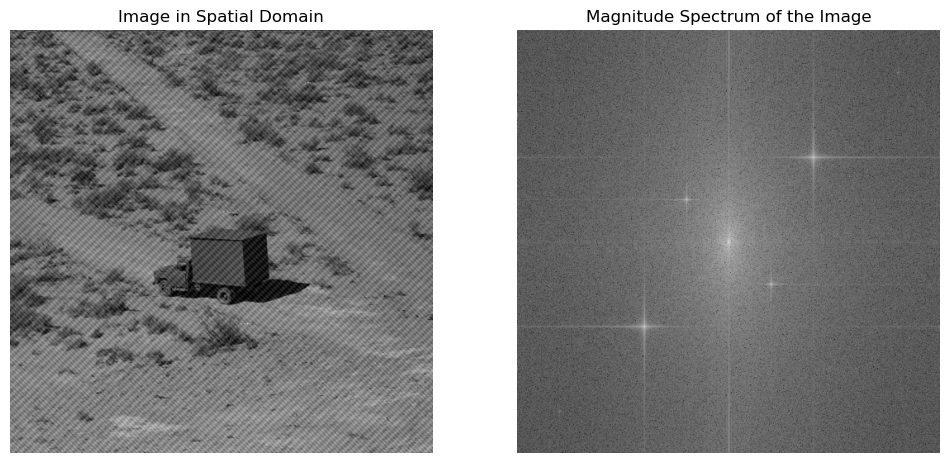

In [8]:
# Answer for A & B : Computing the magnitude spectrum and identifying the type of noise.
ex4_image = Image.open('./imgs/trucknoise.gif')
ex4_image = np.array(ex4_image)
ex4_fft = np.fft.fft2(ex4_image)
ex4_shift = np.fft.fftshift(ex4_fft)
ex4_magnitude = np.abs(ex4_shift)

plt.figure(figsize=(12,8))

plt.subplot(1,2,1)
plt.title('Image in Spatial Domain')
plt.axis('off')
plt.imshow(ex4_image, cmap='gray')

plt.subplot(1,2,2)
plt.title('Magnitude Spectrum of the Image')
plt.axis('off')
plt.imshow(np.log1p(ex4_magnitude), cmap='gray');
#plt.savefig('./results/q4-1.jpg', format='jpg', bbox_inches="tight", pad_inches=0)

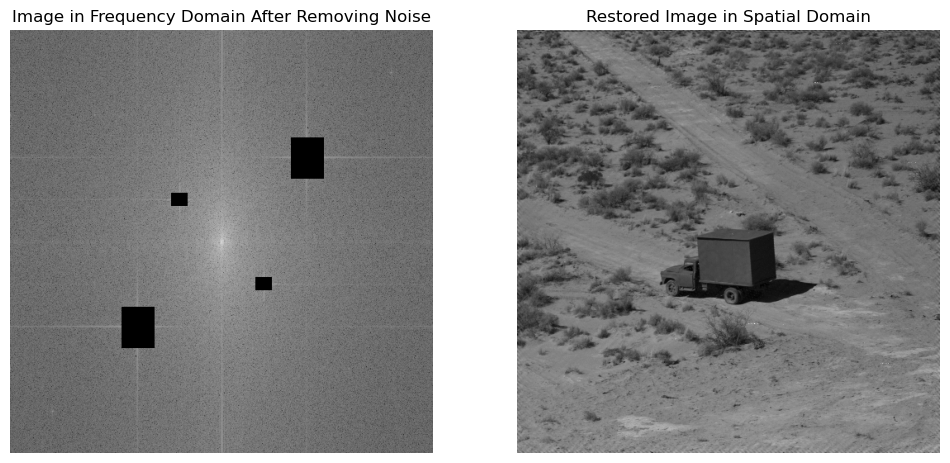

In [9]:
# Answer for C : Removing periodic noise using frequency-domain filtering.
ex4_shift[335:385, 135:175] = 0
ex4_shift[130:180, 340:380] = 0
ex4_shift[197:213, 195:215] = 0
ex4_shift[299:315, 297:317] = 0

ex4_removed_spatial_final = freq_to_spatial(ex4_shift)

plt.figure(figsize=(12, 6))

plt.subplot(1, 2, 1)
plt.title('Image in Frequency Domain After Removing Noise')
plt.axis('off')
plt.imshow(np.log1p(np.abs(ex4_shift)), cmap='gray')

plt.subplot(1, 2, 2)
plt.title('Restored Image in Spatial Domain')
plt.axis('off')
plt.imshow(np.clip(ex4_removed_spatial_final, 0, 255), cmap='gray');

#plt.savefig('./results/q4-2.jpg', format='jpg', bbox_inches="tight", pad_inches=0)

In [10]:
# Answer for D : Displaying the restored image and calculating the PSNR to evaluate the restoration.

ex4_original = Image.open('./imgs/truck.gif')
ex4_original = np.array(ex4_original)

ex4_restored = np.clip(ex4_removed_spatial_final, 0, 255)

psnr_noisy = cv2.PSNR(ex4_original.astype(np.float64), ex4_image.astype(np.float64))

psnr_restored = cv2.PSNR(ex4_original.astype(np.float64), ex4_restored.astype(np.float64))

print('PSNR of the noisy image:', psnr_noisy)
print('PSNR of the restored image:', psnr_restored)

PSNR of the noisy image: 24.595426932492288
PSNR of the restored image: 40.81039204908024
